<a href="https://colab.research.google.com/github/delaneydow/ncl_diffusion/blob/main/03_train_gan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Train the GAN baseline (label-conditional)

Same data, same train split, same multi-hot label conditioning as the diffusion model, so the comparison is fair.
Architecture: ResNet generator + projection discriminator, hinge loss, spectral norm, DiffAugment, EMA generator
(see `models/gan.py`). Runs in fp32 (spectral norm + fp16 can be touchy).

GANs have no validation loss that means anything, so pick checkpoints by FID (optional callback below) and by eye.
Resumes automatically from `ckpt_last.pt`.

In [ ]:
# ====== BOOTSTRAP (identical in every notebook) ======
# Mounts Drive, links the project folder, installs anything missing, puts the package on sys.path.
import os, sys, importlib.util, importlib.metadata, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules

PROJECT = "/content/drive/MyDrive/ncl_diffusion" if IN_COLAB else os.path.abspath("ct_diffusion_project")
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(PROJECT, exist_ok=True)
LINK = "/content/ncl_diffusion_project" if IN_COLAB else PROJECT   # short path used everywhere below
if LINK != PROJECT and not os.path.exists(LINK):
    os.symlink(PROJECT, LINK)

# pip name -> import name.
# NOTE: no `monai-generative` any more. MONAI >= 1.4 ships the diffusion code in core.
_pip = {"einops": "einops", "pydicom": "pydicom", "kaggle": "kaggle", "scikit-learn": "sklearn", "tqdm": "tqdm",
        "opencv-python-headless": "cv2", "pandas": "pandas", "matplotlib": "matplotlib",
        "torchmetrics": "torchmetrics", "torch-fidelity": "torch_fidelity"}
_missing = [p for p, m in _pip.items() if importlib.util.find_spec(m) is None]
try:
    from packaging.version import Version
    _monai_ok = Version(importlib.metadata.version("monai")) >= Version("1.4")
except Exception:          # not installed, or version string we can't parse
    _monai_ok = False
if not _monai_ok:
    _missing.append("monai>=1.4")
if _missing:
    print("installing:", _missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
if LINK not in sys.path:
    sys.path.insert(0, LINK)
print("project:", PROJECT)

Mounted at /content/drive
installing: ['pydicom', 'torchmetrics', 'torch-fidelity', 'monai>=1.4']
project: /content/drive/MyDrive/ncl_diffusion


In [ ]:
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from glob import glob
from IPython.display import Image, display
from ncl_diffusion.config import Config
from ncl_diffusion import data, models, train, synth
from ncl_diffusion.data import load_cache, make_dataset, make_loader
from ncl_diffusion.models import GANSystem
from ncl_diffusion.train import train_gan, load_gan
from ncl_diffusion.registry import LABEL_PLANS
from ncl_diffusion.utils import get_device, count_params, seed_everything, show_grid, to_unit_range

device = get_device()
print("device:", device, torch.cuda.get_device_name(0) if device == "cuda" else "(switch the runtime to GPU!)")

device: cuda NVIDIA RTX PRO 6000 Blackwell Server Edition


In [ ]:
import json, math

VARIANT      = "full_head"                 # which cache to train on: "full_head" or "skull_stripped"
DIFF_RUN     = "ddpm_base_full_head"       # the diffusion run to match (its rows_used.csv defines the training rows)
TARGET_STEPS = 30_000                      # generator steps; see note below

cfg = Config.load(Path(LINK) / "config.json")
cfg.paths.project = LINK
SMOKE = False

# rows: exactly the slices the diffusion run trained on
used = pd.read_csv(cfg.run_dir(DIFF_RUN) / "rows_used.csv")
healthy_only = bool((used["any"] == 0).all())

cfg = cfg.override({
    "gan.run_name": f"cgan_{'smoke' if SMOKE else 'base'}_{VARIANT}{'_healthy' if healthy_only else ''}",
    "gan.epochs": 3 if SMOKE else 150,     # replaced below once steps per epoch are known
    "gan.sample_every": 1 if SMOKE else 5,
    "gan.batch_size": 32,                # lower this if you hit CUDA out-of-memory (the GAN runs in fp32)
})
seed_everything(cfg.data.seed)
run_dir = cfg.run_dir(cfg.gan.run_name); run_dir.mkdir(parents=True, exist_ok=True)
used.to_csv(run_dir / "rows_used.csv", index=False)

variants = json.loads((Path(LINK) / "cache_variants.json").read_text())
images, man = load_cache(Path(variants[VARIANT]))
man = man[man.sample_id.isin(used.sample_id)]
print(f"{VARIANT}: {len(man)} rows | healthy_only={healthy_only}\n{man.split.value_counts().to_string()}")
assert len(man) == len(used), "some rows from the diffusion run are missing in this cache"

lc, in_ch = cfg.data.label_cols, images.shape[1]
train_ds = make_dataset(images, man, "train", lc)
train_loader = make_loader(train_ds, cfg.gan.batch_size, True, cfg.data.num_workers, drop_last=True)

EPOCHS = 3 if SMOKE else math.ceil(TARGET_STEPS / len(train_loader))
cfg = cfg.override({"gan.epochs": EPOCHS})
cfg.save(run_dir / "config.json")
print(f"train {len(train_ds)} | {EPOCHS} epochs = {EPOCHS * len(train_loader):,} generator steps")

# row-alignment check: should print ~0
r = man[man.split == "train"].iloc[0]
print("alignment check:", float(np.abs(train_ds[0]["image"].numpy().ravel() * 255 - images[r.idx].ravel()).max()))

system = GANSystem(cfg, in_ch, len(lc))
print(f"G {count_params(system.G) / 1e6:.1f} M params | D {count_params(system.D) / 1e6:.1f} M params")
preview = (np.zeros((24, len(lc))) if healthy_only
           else LABEL_PLANS.build("balance", man[man.split == "train"], lc, 24, cfg.data.seed))

full_head: 8007 rows | healthy_only=False
split
train    5548
test     1652
val       807
train 5548 | 174 epochs = 30,102 generator steps
alignment check: 0.0
G 10.3 M params | D 14.8 M params


## Optional: FID during training
Off by default (`FID_EVERY = 0`). When on, FID is computed every `FID_EVERY` epochs on 1000 EMA samples vs. real train
images and the best checkpoint is kept as `ckpt_best.pt`. With only 1000 samples FID is noisy and biased, so use it to
compare checkpoints of the same run, not as a final number. It also uses ImageNet Inception features (fine for picking
checkpoints, not for the final evaluation, where we will add medical-image features).

In [ ]:
from ncl_diffusion.metrics import fid_score

FID_EVERY = 0            # e.g. 10 to turn on
N_FID = 1000
tr = man[man.split == "train"]
real_u8 = images[tr.idx.to_numpy()[:N_FID * 2]]
fid_labels = LABEL_PLANS.build("match_dist", tr, lc, N_FID, 0)     # same label mix as the real data

def fid_eval(system):
    system.eval()
    fake = []
    for i in range(0, N_FID, 100):
        x = system.sample(torch.tensor(fid_labels[i:i + 100]).float().to(device))
        fake.append(((x + 1) / 2 * 255).round().byte().cpu().numpy())
    return {"fid": fid_score(real_u8, np.concatenate(fake), device=device, max_n=N_FID)}

## Train
Columns: `lossD` / `lossG` (hinge losses), `d_real` / `d_fake` (mean discriminator scores). Healthy GAN training has
`d_real` a bit above `d_fake` and both hovering, not diverging. If `d_fake` keeps dropping towards very negative values
and images degrade, D is winning: try the knobs above.

In [ ]:
hist = train_gan(system, train_loader, cfg, run_dir, device, preview_labels=preview,
                 eval_fn=fid_eval if FID_EVERY else None, eval_every=FID_EVERY)

epoch 1/174:   0%|          | 0/173 [00:00<?, ?it/s]

{'epoch': 1, 'lossD': 2.2302, 'lossG': 0.3055, 'd_real': -0.1261, 'd_fake': -0.1923}


epoch 2/174:   0%|          | 0/173 [00:00<?, ?it/s]

{'epoch': 2, 'lossD': 1.785, 'lossG': 0.6475, 'd_real': 0.5732, 'd_fake': -0.3126}


epoch 3/174:   0%|          | 0/173 [00:00<?, ?it/s]

...

{'epoch': 172, 'lossD': 2.0, 'lossG': 0.17, 'd_real': -0.1696, 'd_fake': -0.1696}


epoch 173/174:   0%|          | 0/173 [00:00<?, ?it/s]

{'epoch': 173, 'lossD': 2.0001, 'lossG': 0.0578, 'd_real': -0.0589, 'd_fake': -0.0589}


epoch 174/174:   0%|          | 0/173 [00:00<?, ?it/s]

{'epoch': 174, 'lossD': 2.0, 'lossG': 0.0384, 'd_real': -0.0384, 'd_fake': -0.0384}


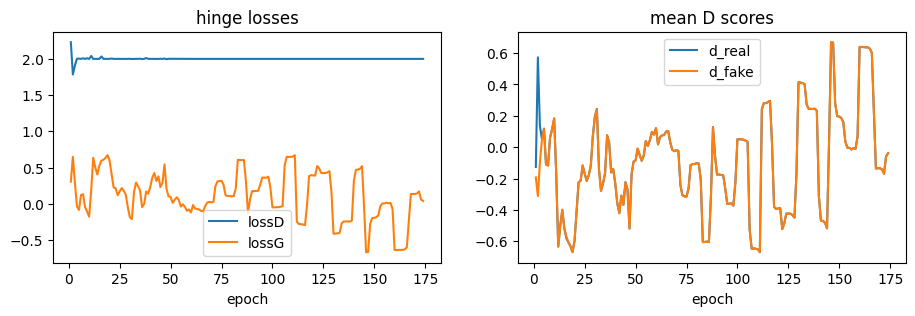

latest preview: /content/ncl_diffusion_project/runs/cgan_base_full_head/samples/ep174.png


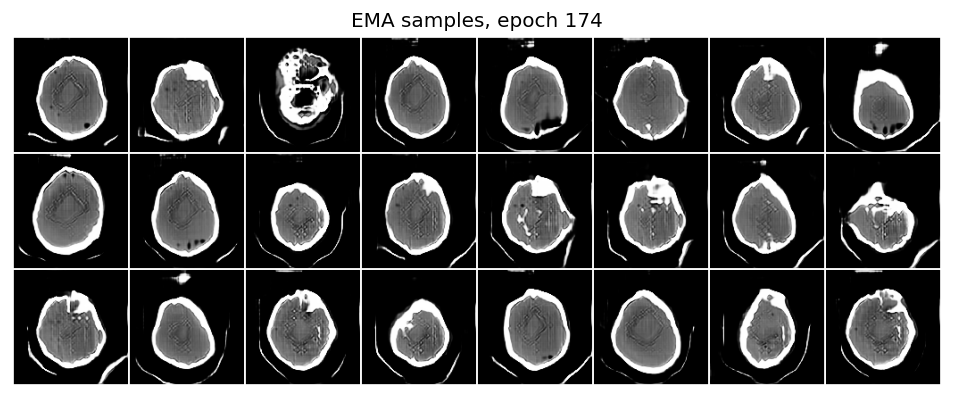

In [ ]:
h = pd.read_csv(run_dir / "history.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
h.plot(x="epoch", y=["lossD", "lossG"], ax=ax[0], title="hinge losses")
h.plot(x="epoch", y=["d_real", "d_fake"], ax=ax[1], title="mean D scores")
plt.show()

latest = sorted(glob(str(run_dir / "samples" / "*.png")))
if latest:
    print("latest preview:", latest[-1]); display(Image(latest[-1]))

## Diversity check (quick, by eye)
GANs can collapse onto a few modes. Same label, 16 different noise vectors: if the images are near-identical, that's
mode collapse (the paper's SPADE/Pix2Pix had an MS-SSIM diversity of about 1.0, which is why they made poor augmenters).

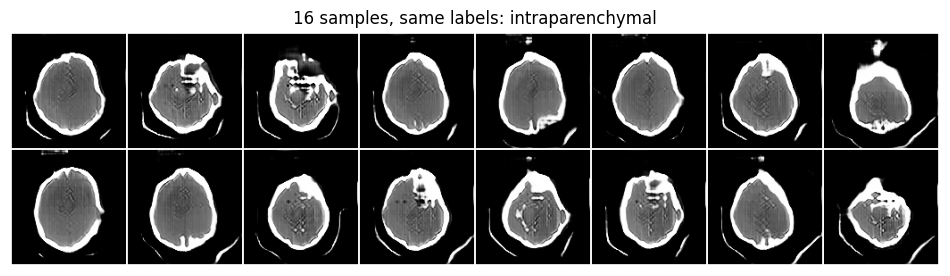

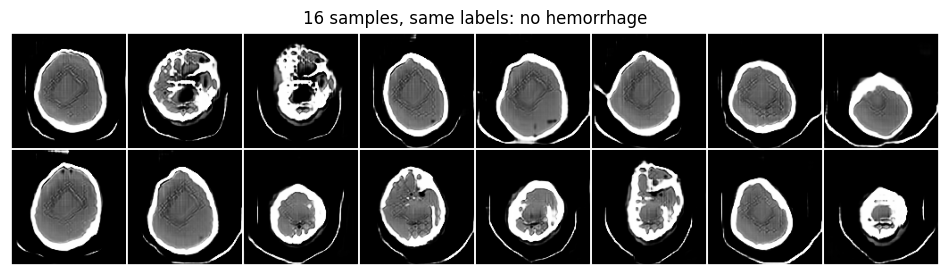

In [ ]:
gan_sys = load_gan(cfg, run_dir, in_ch, len(lc), device, which="last")
for name, row in [("intraparenchymal", [0, 1, 0, 0, 0, 1]), ("no hemorrhage", [0, 0, 0, 0, 0, 0])]:
    lab = torch.tensor([row] * 16).float()
    x = gan_sys.sample(lab, generator=torch.Generator(device).manual_seed(0))
    show_grid(to_unit_range(x).cpu(), nrow=8, title=f"16 samples, same labels: {name}", figsize=(12, 3.2))

**Next:** generation and evaluation. Both generators expose the same `.sample(labels, ...)`, so
`synth.generate_synthetic(system, labels, cfg.sample, label_cols, out_dir)` works for either one and writes the same
cache format the classifier experiments and metrics read.